# Run 2D correction

Compute and save the bare parameters used by the 2D corrected simulation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np

resol = 160
plt.rcParams.update({
    "font.family": "serif",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

cwd = Path().resolve()
setup_root = next(
    (
        path
        for path in (cwd, *cwd.parents)
        if (path / "database_fiber").exists() and (path / "src").exists()
    ),
    Path("2d_setup").resolve(),
)
sys.path.insert(0, str(setup_root))

from src.bare_param import (
    bare_param_path,
    get_2d_bare_parameters,
    load_bare_parameters_csv,
    read_bare_parameters_metadata,
    read_target_profile_metadata,
    save_bare_parameters_csv,
    target_profile_path,
)
from src.generate_fiber_geom import load_geometry_by_id

pi = np.pi


<h2>Load geometry</h2>

In [2]:
geometry_id = 5
geometry = load_geometry_by_id(geometry_id)

L1, L2 = geometry["lengths"]
N_A = geometry["N_A"]
atom_positions = geometry["atom_positions"]

print(f"Loaded geometry: {geometry['path'].name}")
print(f"lengths={geometry['lengths']}, N_A={N_A}, N_layer={geometry['N_layer']}, kind={geometry['kind']}")

Loaded geometry: geometry_id5.csv
lengths=[5. 5.], N_A=10, N_layer=1, kind=slab


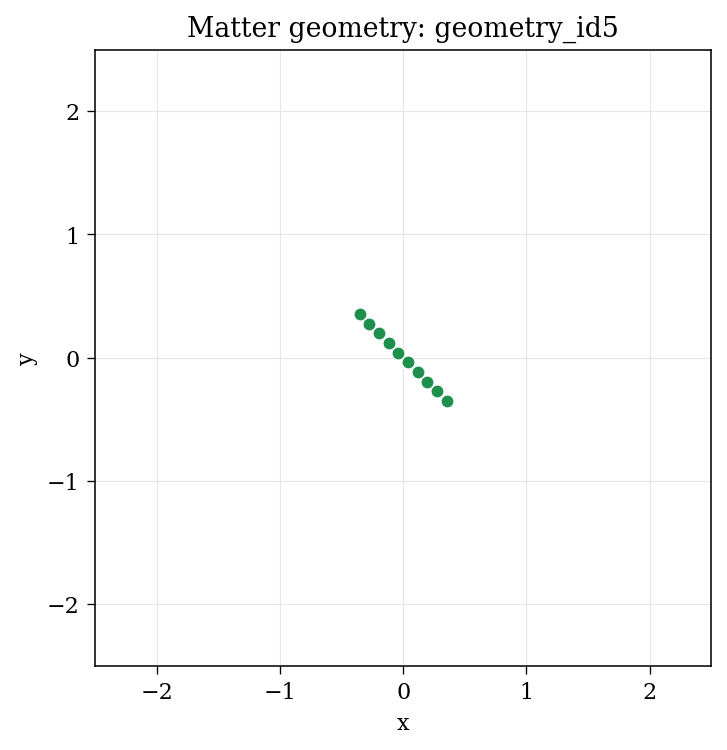

In [3]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
ax.scatter(
    atom_positions[:, 0],
    atom_positions[:, 1],
    s=34,
    color="#1f8f4d",
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)
ax.set_xlim(-L1 / 2, L1 / 2)
ax.set_ylim(-L2 / 2, L2 / 2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(color="0.9", linewidth=0.5)
ax.set_title(f"Matter geometry: {geometry['label']}")
plt.show()


<h2>Correction inputs</h2>

In [17]:
Omega_A_tab = 10 * np.pi * np.ones(N_A)
d_A_tab = np.ones(N_A, dtype=float)
id_target_profile = 1

cutoffs = {
    "ir_cutoff": 5 * np.pi,
    "uv_cutoff": 14 * np.pi,
}

target_profile_csv = target_profile_path(id_target_profile)

if not target_profile_csv.exists():
    raise FileNotFoundError(f"Missing target_profile_id{id_target_profile}.csv.")

target_metadata = read_target_profile_metadata(target_profile_csv)
print(f"Target profile CSV: {target_profile_csv}")
print(f"Simulation window: [{cutoffs['ir_cutoff'] / np.pi:.6g} pi, {cutoffs['uv_cutoff'] / np.pi:.6g} pi]")


Target profile CSV: /Users/romainpiron/Documents/NII_local/waveguide-qed-simulator/2d_setup/database_fiber/target_profiles/target_profile_id1.csv
Simulation window: [5 pi, 14 pi]


<h2>Run optimization</h2>

In [18]:
Omega_0_tab, d_0_tab = get_2d_bare_parameters(
    target_profile_csv,
    atom_positions,
    cutoffs,
)

print(f"Omega_0/pi range: {np.min(Omega_0_tab) / np.pi:.6g} -- {np.max(Omega_0_tab) / np.pi:.6g}")
print(f"d_0 range: {np.min(d_0_tab):.6g} -- {np.max(d_0_tab):.6g}")


Omega_0/pi range: 8.28048 -- 8.42325
d_0 range: 0.863061 -- 0.937504


<h2>Save bare parameters</h2>

In [19]:
output_path = bare_param_path()
save_bare_parameters_csv(Omega_0_tab, d_0_tab, target_metadata, cutoffs, output_path)

print(f"Saved bare parameters to: {output_path}")


Saved bare parameters to: /Users/romainpiron/Documents/NII_local/waveguide-qed-simulator/2d_setup/database_fiber/bare_param/bare_param_id4.csv


<h2>Bare parameters</h2>

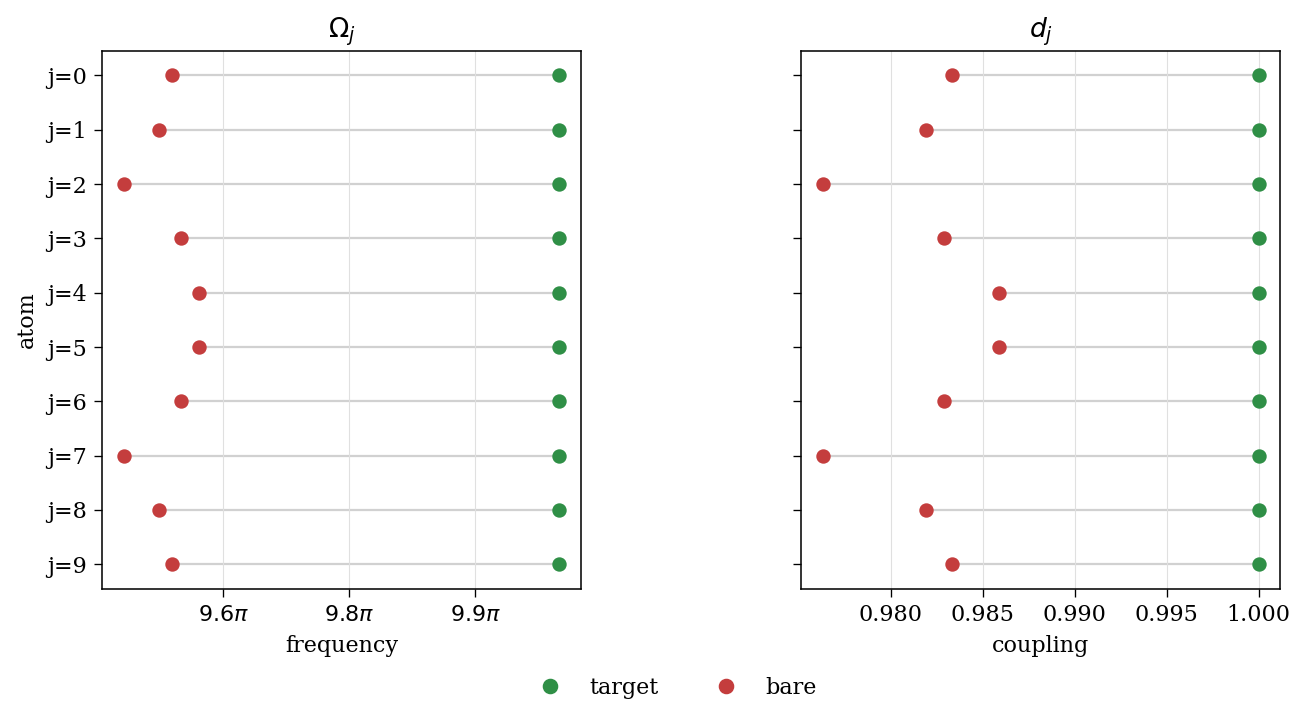

In [20]:
bare_param_id_to_plot = 2
bare_param_csv = bare_param_path(bare_param_id_to_plot)
if not bare_param_csv.exists():
    raise FileNotFoundError(f"Missing bare_param_id{bare_param_id_to_plot}.csv.")

bare_metadata = read_bare_parameters_metadata(bare_param_csv)
Omega_0_tab, d_0_tab = load_bare_parameters_csv(bare_param_csv)
Omega_A_tab = bare_metadata["Omega_A"]
d_A_tab = bare_metadata["d_A"]
N_A = len(Omega_0_tab)

atom_index = np.arange(N_A)
omega_target = Omega_A_tab / np.pi
omega_optimized = Omega_0_tab / np.pi
d_target = d_A_tab
d_optimized = d_0_tab

def pi_formatter(value, _):
    n = value
    if np.isclose(n, 0):
        return "0"
    if np.isclose(n, 1):
        return r"$\pi$"
    if np.isclose(n, -1):
        return r"$-\pi$"
    if np.isclose(n, round(n)):
        return rf"${int(round(n))}\pi$"
    return rf"${n:.1f}\pi$"

fig, (omega_ax, d_ax) = plt.subplots(
    1,
    2,
    figsize=(9.5, max(3.4, 0.34 * N_A + 1.4)),
    dpi=resol,
    gridspec_kw={"wspace": 0.46},
)

omega_ax.hlines(atom_index, np.minimum(omega_target, omega_optimized), np.maximum(omega_target, omega_optimized), color="0.82", linewidth=1.0, zorder=1)
omega_ax.scatter(omega_target, atom_index, color="#2f8f46", s=30, zorder=3)
omega_ax.scatter(omega_optimized, atom_index, color="#c43d3d", s=30, zorder=3)
omega_ax.set_title(r"$\Omega_j$")
omega_ax.set_xlabel(r"frequency")
omega_ax.set_ylabel("atom")
omega_ax.set_yticks(atom_index)
omega_ax.set_yticklabels([f"j={j}" for j in atom_index])
omega_ax.invert_yaxis()
omega_ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
omega_ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))
omega_ax.grid(axis="x", color="0.88", linewidth=0.5)

d_ax.hlines(atom_index, np.minimum(d_target, d_optimized), np.maximum(d_target, d_optimized), color="0.82", linewidth=1.0, zorder=1)
d_ax.scatter(d_target, atom_index, color="#2f8f46", s=30, zorder=3)
d_ax.scatter(d_optimized, atom_index, color="#c43d3d", s=30, zorder=3)
d_ax.set_title(r"$d_j$")
d_ax.set_xlabel(r"coupling")
d_ax.set_yticks(atom_index)
d_ax.set_yticklabels([])
d_ax.invert_yaxis()
d_ax.grid(axis="x", color="0.88", linewidth=0.5)

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#2f8f46", markeredgecolor="#2f8f46", markersize=6, label="target"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#c43d3d", markeredgecolor="#c43d3d", markersize=6, label="bare"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.01))
fig.subplots_adjust(bottom=0.18)
plt.show()
